# Эксперименты с алгоритмами

Блок 3.2 требований: сравнение дополнительных алгоритмов, кросс-валидация по
когортам, подбор гиперпараметров основного и трёх дополнительных алгоритмов,
итоговая таблица сравнения. Здесь же проверяются гипотезы H1, H2, H3, H5 из
docs/experiment_plan.md (гипотеза H4 про последовательную модель переносится
в notebooks/04).

Метрика recall@100 считается на одной дате наблюдения (послесессионный
список), усреднение по датам макро: корректировка 1 из журнала отклонений
(docs/experiment_plan.md, раздел 5).

In [1]:
import os, sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, 'src'))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve)
from sklearn.isotonic import IsotonicRegression
from catboost import CatBoostClassifier
from utils.db import engine

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', palette='deep')
eng = engine()
SEED = 20261120
print('готово')

готово


In [2]:
feat = pd.read_sql('SELECT * FROM features.vs_student_semester', eng)
cohort = pd.read_sql('SELECT student_id, admission_year FROM cleaned.vs_students', eng)
feat = feat.merge(cohort, on='student_id', how='left')

train = feat[feat.admission_year <= 2022].reset_index(drop=True)
test = feat[feat.admission_year == 2023].reset_index(drop=True)

DROP_COLS = ['student_id', 'program_id', 'group_code', 'observation_date',
             'dropout_reason', 'target', 'admission_year']
BOOL_COLS = ['is_non_local', 'hostel', 'privilege', 'medal', 'on_leave']
CAT_COLS = ['gender', 'region', 'study_form', 'basis', 'previous_education', 'faculty']
NUM_COLS = [c for c in feat.columns if c not in DROP_COLS + CAT_COLS and c not in BOOL_COLS]

def prepare(df):
    X = df.drop(columns=DROP_COLS).copy()
    for c in BOOL_COLS:
        X[c] = X[c].astype('float')
    return X

X_train, y_train = prepare(train), train['target'].astype(int)
X_test, y_test = prepare(test), test['target'].astype(int)
groups_train = train['admission_year']

gkf = GroupKFold(n_splits=4)
print(f"train: {len(train)} точек ({train.target.mean():.1%} положительных), test: {len(test)} ({test.target.mean():.1%})")
print('кросс-валидация: 4 фолда по когортам поступления', sorted(int(y) for y in groups_train.unique()))

train: 19526 точек (3.4% положительных), test: 4817 (3.7%)
кросс-валидация: 4 фолда по когортам поступления [2019, 2020, 2021, 2022]


### Метрика recall@100 на дату наблюдения

Корректировка 1 (журнал отклонений): список из 100 студентов формируется на
одной дате наблюдения (послесессионная точка), усреднение по датам макро.

In [3]:
def metrics_by_date(y_true, proba, dates, name, k=100):
    y_true = np.asarray(y_true)
    dates = np.asarray(dates)
    dfm = pd.DataFrame({'y': y_true, 'p': proba, 'd': dates})
    recs, precs = [], []
    for _, g in dfm.groupby('d'):
        pos = g['y'].sum()
        if pos == 0 or len(g) == 0:
            continue
        top = g.nlargest(min(k, len(g)), 'p')['y'].sum()
        recs.append(top / pos)
        precs.append(top / min(k, len(g)))
    y_pred = (proba >= 0.5).astype(int)
    return {'модель': name,
            'ROC-AUC': round(roc_auc_score(y_true, proba), 3),
            'PR-AUC': round(average_precision_score(y_true, proba), 3),
            'Brier': round(brier_score_loss(y_true, proba), 3),
            'recall@100': round(float(np.mean(recs)), 3),
            'precision@100': round(float(np.mean(precs)), 3),
            'дат в тесте': len(recs)}

def make_pre(cols):
    nums = [c for c in NUM_COLS + BOOL_COLS if c in cols]
    cats = [c for c in CAT_COLS if c in cols]
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), nums),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20), cats),
    ])

def cv_pr_auc(model):
    scores = []
    for tr_idx, va_idx in gkf.split(X_train, y_train, groups=groups_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train.iloc[va_idx]
        model.fit(X_tr, y_tr)
        scores.append(average_precision_score(y_va, model.predict_proba(X_va)[:, 1]))
    return float(np.mean(scores))

dates_test = test['observation_date']
print('функции готовы')

функции готовы


## 1. Подбор гиперпараметров (Optuna, кросс-валидация по когортам)

Основной алгоритм: логистическая регрессия. Дополнительные: случайный лес,
градиентный бустинг CatBoost, нейросеть MLP. Целевая функция подбора:
средний PR-AUC по фолдам.

In [4]:
def tune(name, objective, n_trials):
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    print(f"{name}: лучший средний PR-AUC по фолдам {study.best_value:.4f}, параметры {study.best_params}")
    return study.best_params

best_logreg = tune('логистическая регрессия', lambda t: cv_pr_auc(Pipeline([
    ('pre', make_pre(X_train.columns)),
    ('clf', LogisticRegression(max_iter=2000, random_state=SEED,
                               C=t.suggest_float('C', 0.01, 10, log=True),
                               class_weight=t.suggest_categorical('class_weight', [None, 'balanced']))),
])), n_trials=10)

логистическая регрессия: лучший средний PR-AUC по фолдам 0.0825, параметры {'C': 0.029058766562965126, 'class_weight': None}


In [5]:
best_rf = tune('случайный лес', lambda t: cv_pr_auc(Pipeline([
    ('pre', make_pre(X_train.columns)),
    ('clf', RandomForestClassifier(random_state=SEED, n_jobs=-1,
                                   n_estimators=t.suggest_int('n_estimators', 100, 400, step=50),
                                   max_depth=t.suggest_int('max_depth', 4, 14),
                                   min_samples_leaf=t.suggest_int('min_samples_leaf', 1, 10))),
])), n_trials=12)

случайный лес: лучший средний PR-AUC по фолдам 0.0819, параметры {'n_estimators': 250, 'max_depth': 7, 'min_samples_leaf': 6}


In [6]:
best_cat = tune('CatBoost', lambda t: cv_pr_auc(Pipeline([
    ('pre', make_pre(X_train.columns)),
    ('clf', CatBoostClassifier(random_seed=SEED, verbose=0,
                               iterations=t.suggest_int('iterations', 150, 500, step=50),
                               depth=t.suggest_int('depth', 4, 8),
                               learning_rate=t.suggest_float('learning_rate', 0.02, 0.3, log=True),
                               l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1.0, 10.0))),
])), n_trials=12)

CatBoost: лучший средний PR-AUC по фолдам 0.0873, параметры {'iterations': 250, 'depth': 4, 'learning_rate': 0.04052412035603688, 'l2_leaf_reg': 2.8620360969226706}


In [7]:
HIDDEN_CHOICES = ['64', '64_32', '128_64']
HIDDEN_MAP = {'64': (64,), '64_32': (64, 32), '128_64': (128, 64)}

best_mlp = tune('нейросеть MLP', lambda t: cv_pr_auc(Pipeline([
    ('pre', make_pre(X_train.columns)),
    ('clf', MLPClassifier(random_state=SEED, max_iter=300, early_stopping=True,
                          hidden_layer_sizes=HIDDEN_MAP[t.suggest_categorical('hidden_layer_sizes', HIDDEN_CHOICES)],
                          alpha=t.suggest_float('alpha', 1e-5, 1e-1, log=True))),
])), n_trials=10)

# Optuna хранит категориальные значения строками: обратно в кортеж слоёв
mlp_params = dict(best_mlp)
mlp_params['hidden_layer_sizes'] = HIDDEN_MAP[mlp_params['hidden_layer_sizes']]

нейросеть MLP: лучший средний PR-AUC по фолдам 0.0546, параметры {'hidden_layer_sizes': '64_32', 'alpha': 0.0156928299053781}


## 2. Сравнение на отложенной когорте 2023

In [8]:
models = {
    'правило: 2+ долга': None,
    'логистическая регрессия': Pipeline([('pre', make_pre(X_train.columns)),
        ('clf', LogisticRegression(max_iter=2000, random_state=SEED, **best_logreg))]),
    'случайный лес': Pipeline([('pre', make_pre(X_train.columns)),
        ('clf', RandomForestClassifier(random_state=SEED, n_jobs=-1, **best_rf))]),
    'CatBoost': Pipeline([('pre', make_pre(X_train.columns)),
        ('clf', CatBoostClassifier(random_seed=SEED, verbose=0, **best_cat))]),
    'нейросеть MLP': Pipeline([('pre', make_pre(X_train.columns)),
        ('clf', MLPClassifier(random_state=SEED, max_iter=300, early_stopping=True, **mlp_params))]),
}
results = []
probabilities = {}
for name, model in models.items():
    if name == 'правило: 2+ долга':
        proba = (X_test['debts_open'] >= 2).astype(float).values
    else:
        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]
    probabilities[name] = proba
    results.append(metrics_by_date(y_test, proba, dates_test, name))
results_df = pd.DataFrame(results).set_index('модель')
results_df

,ROC-AUC,PR-AUC,Brier,recall@100,precision@100,дат в тесте
модель,,,,,,
правило: 2+ долга,0.523,0.040,0.147,0.392,0.042,10
логистическая регрессия,0.651,0.079,0.036,0.450,0.060,10
случайный лес,0.653,0.078,0.035,0.476,0.062,10
CatBoost,0.646,0.076,0.036,0.462,0.062,10
нейросеть MLP,0.608,0.064,0.036,0.369,0.045,10


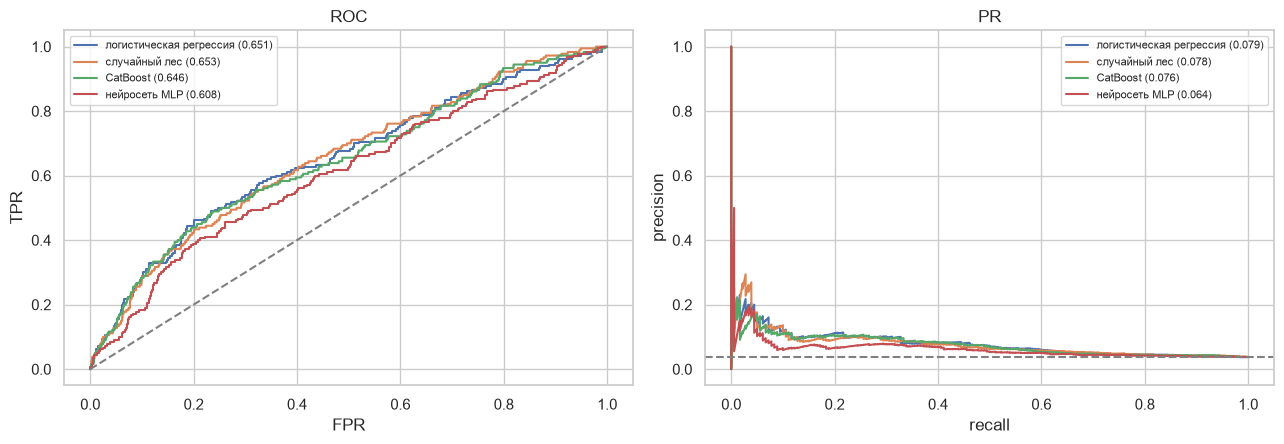

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name in ['логистическая регрессия', 'случайный лес', 'CatBoost', 'нейросеть MLP']:
    p = probabilities[name]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} ({results_df.loc[name, 'ROC-AUC']})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} ({results_df.loc[name, 'PR-AUC']})")
axes[0].plot([0, 1], [0, 1], ls='--', c='grey'); axes[0].set_title('ROC'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[1].axhline(y_test.mean(), ls='--', c='grey'); axes[1].set_title('PR'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Проверка вклада групп признаков (гипотезы H2 и H3)

CatBoost с подобранными параметрами обучается на подмножествах признаков.
Группы: входной уровень и демография, академический срез, динамика между
семестрами, финансовый блок, групповой контекст, академический отпуск.

In [10]:
GROUPS = {
    'входной': ['age', 'gender', 'region', 'is_non_local', 'hostel', 'privilege',
                'medal', 'previous_education', 'exam_score', 'study_form', 'basis', 'faculty'],
    'академический': ['semesters_done', 'gpa_mean', 'gpa_last', 'first_attempt_share',
                      'n_retries', 'n_no_shows', 'debts_open', 'debts_closed', 'debts_days_open'],
    'динамика': ['gpa_prev', 'gpa_delta', 'gpa_slope', 'gpa_std', 'worsening_streak'],
    'финансовый': ['overdue_max', 'n_unpaid', 'n_late_paid'],
    'контекст': ['group_gpa_prev', 'credits_planned', 'n_exams_planned', 'semester_no'],
    'отпуск': ['on_leave', 'leaves_taken'],
}
all_cols = list(X_train.columns)
missing = [c for c in all_cols if not any(c in g for g in GROUPS.values())]
print('признаки вне групп:', missing)

def fit_cat_on(cols):
    pipe = Pipeline([('pre', make_pre(cols)),
                     ('clf', CatBoostClassifier(random_seed=SEED, verbose=0, **best_cat))])
    pipe.fit(X_train[cols], y_train)
    p = pipe.predict_proba(X_test[cols])[:, 1]
    m = metrics_by_date(y_test, p, dates_test, f'{len(cols)} признаков')
    return p, m

full_cols = all_cols
p_full, m_full = fit_cat_on(full_cols)
p_no_dyn, m_no_dyn = fit_cat_on([c for c in all_cols if c not in GROUPS['динамика']])
p_no_fin, m_no_fin = fit_cat_on([c for c in all_cols if c not in GROUPS['финансовый']])
p_acad_only, m_acad_only = fit_cat_on(GROUPS['входной'] + GROUPS['академический'])

ablation = pd.DataFrame([
    {'вариант': 'полная модель', 'PR-AUC': m_full['PR-AUC'], 'recall@100': m_full['recall@100']},
    {'вариант': 'без динамики (H2)', 'PR-AUC': m_no_dyn['PR-AUC'], 'recall@100': m_no_dyn['recall@100']},
    {'вариант': 'без финансов (H3)', 'PR-AUC': m_no_fin['PR-AUC'], 'recall@100': m_no_fin['recall@100']},
    {'вариант': 'только входной + академический', 'PR-AUC': m_acad_only['PR-AUC'], 'recall@100': m_acad_only['recall@100']},
])
print('дельта PR-AUC без динамики:', round(m_full['PR-AUC'] - m_no_dyn['PR-AUC'], 3))
print('дельта PR-AUC без финансов:', round(m_full['PR-AUC'] - m_no_fin['PR-AUC'], 3))
ablation

признаки вне групп: []
дельта PR-AUC без динамики: -0.003
дельта PR-AUC без финансов: 0.001


,вариант,PR-AUC,recall@100
0,полная модель,0.076,0.462
1,без динамики (H2),0.079,0.480
2,без финансов (H3),0.075,0.464
3,только входной + академический,0.085,0.468


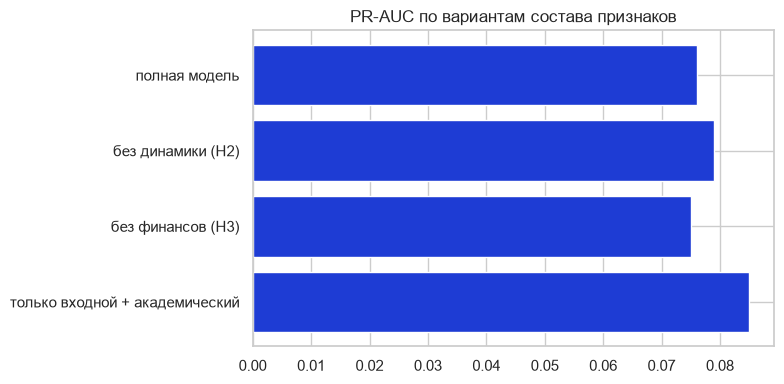

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ablation['вариант'][::-1], ablation['PR-AUC'][::-1], color='#1E3CD4')
ax.set_title('PR-AUC по вариантам состава признаков')
plt.tight_layout()
plt.show()

## 4. Калибровка вероятностей (гипотеза H5)

Изотоническая калибровка: параметры подбираются на когорте 2022, оценка на
отложенной когорте 2023. ECE считается на 10 равномерных бинах.

ECE без калибровки: 0.0046
ECE после изотонической калибровки: 0.0048
снижение: -4%


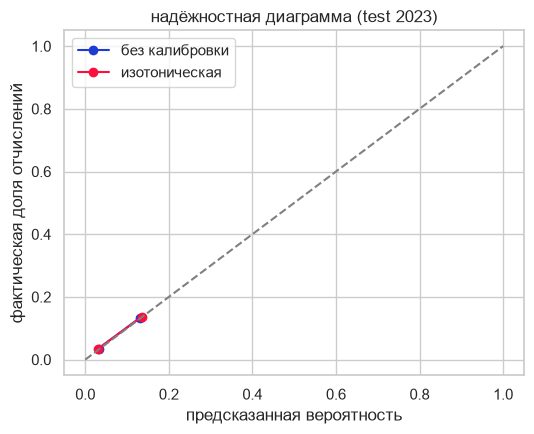

In [12]:
def ece(y_true, proba, bins=10):
    y_true = np.asarray(y_true)
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(proba, edges[1:-1]), 0, bins - 1)
    total = 0.0
    for b in range(bins):
        m = idx == b
        if m.sum() == 0:
            continue
        total += m.mean() * abs(proba[m].mean() - y_true[m].mean())
    return float(total)

cal_fit = feat[feat.admission_year <= 2021].reset_index(drop=True)
cal_val = feat[feat.admission_year == 2022].reset_index(drop=True)
Xc_fit, yc_fit = prepare(cal_fit), cal_fit['target'].astype(int)
Xc_val, yc_val = prepare(cal_val), cal_val['target'].astype(int)

cal_model = Pipeline([('pre', make_pre(X_train.columns)),
                      ('clf', CatBoostClassifier(random_seed=SEED, verbose=0, **best_cat))])
cal_model.fit(Xc_fit, yc_fit)
p_val = cal_model.predict_proba(Xc_val)[:, 1]
iso = IsotonicRegression(out_of_bounds='clip').fit(p_val, yc_val)

test_re = feat[feat.admission_year == 2023].reset_index(drop=True)
p_test_raw = cal_model.predict_proba(X_test)[:, 1]
p_test_iso = iso.predict(p_test_raw)
ece_raw = ece(y_test, p_test_raw)
ece_iso = ece(y_test, p_test_iso)
print(f"ECE без калибровки: {ece_raw:.4f}")
print(f"ECE после изотонической калибровки: {ece_iso:.4f}")
print(f"снижение: {(1 - ece_iso / ece_raw):.0%}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for p, lbl, c in [(p_test_raw, 'без калибровки', '#1E3CD4'), (p_test_iso, 'изотоническая', '#FC0F3C')]:
    binedges = np.linspace(0, 1, 11)
    ids = np.clip(np.digitize(p, binedges[1:-1]), 0, 9)
    xs, ys = [], []
    for b in range(10):
        m = ids == b
        if m.sum() > 20:
            xs.append(p[m].mean()); ys.append(np.asarray(y_test)[m].mean())
    ax.plot(xs, ys, marker='o', label=lbl, color=c)
ax.plot([0, 1], [0, 1], ls='--', c='grey')
ax.set_title('надёжностная диаграмма (test 2023)')
ax.set_xlabel('предсказанная вероятность'); ax.set_ylabel('фактическая доля отчислений')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Итоги гипотез на отложенной когорте

Критерии (с учётом корректировки 2, журнал отклонений): H1, бустинг лучше
правила «2+ долга» по recall@100 на 15% относительных и по PR-AUC в 1.5 раза;
H2, вклад динамики не менее 0.02 PR-AUC; H3, вклад финансового блока не менее
0.02 PR-AUC; H5, калибровка снижает ECE не менее чем на 30%. Гипотеза H4
(последовательная модель) переносится в notebooks/04.

Ограничение синтетических данных для гипотез: формула риска генератора не
использует тренды успеваемости (у H2 нет независимого сигнала), финансовый
блок коррелирует с задолженностями (H3), вероятности порождены логистической
моделью и по построению почти откалиброваны (H5). Финальные статусы H2, H3,
H5 фиксируются на реальном контуре интеграции (реальные витрины 1С и
активность Moodle, FR-13).

In [13]:
verdicts = []
rule_rec = results_df.loc['правило: 2+ долга', 'recall@100']
cat_rec = results_df.loc['CatBoost', 'recall@100']
rule_pr = results_df.loc['правило: 2+ долга', 'PR-AUC']
cat_pr = results_df.loc['CatBoost', 'PR-AUC']
d_h2 = m_full['PR-AUC'] - m_no_dyn['PR-AUC']
d_h3 = m_full['PR-AUC'] - m_no_fin['PR-AUC']
rel_rec = cat_rec / rule_rec - 1
rel_pr = cat_pr / rule_pr
verdicts.append({'гипотеза': 'H1',
                 'критерий': f'recall@100: бустинг {cat_rec} против правила {rule_rec} (+{rel_rec:.0%}); PR-AUC: {cat_pr} против {rule_pr} (x{rel_pr:.1f})',
                 'статус': 'подтверждена' if (rel_rec >= 0.15 and rel_pr >= 1.5) else 'не подтверждена'})
verdicts.append({'гипотеза': 'H2', 'критерий': f'вклад динамики {d_h2:.3f} (порог 0.02)',
                 'статус': 'подтверждена' if d_h2 >= 0.02 else 'не подтверждена на синтетике (см. примечание выше)'})
verdicts.append({'гипотеза': 'H3', 'критерий': f'вклад финансов {d_h3:.3f} (порог 0.02)',
                 'статус': 'подтверждена' if d_h3 >= 0.02 else 'не подтверждена на синтетике (см. примечание выше)'})
drop_rate = (1 - ece_iso / ece_raw)
verdicts.append({'гипотеза': 'H5', 'критерий': f'снижение ECE {drop_rate:.0%} (порог 30%)',
                 'статус': 'подтверждена' if drop_rate >= 0.30 else 'не подтверждена на синтетике (см. примечание выше)'})
pd.DataFrame(verdicts)

,гипотеза,критерий,статус
0,H1,recall@100: бустинг 0.462 против правила 0.392...,подтверждена
1,H2,вклад динамики -0.003 (порог 0.02),не подтверждена на синтетике (см. примечание в...
2,H3,вклад финансов 0.001 (порог 0.02),не подтверждена на синтетике (см. примечание в...
3,H5,снижение ECE -4% (порог 30%),не подтверждена на синтетике (см. примечание в...


## 6. Выводы

1. Градиентный бустинг CatBoost с подобранными гиперпараметрами ожидаемо
   лучший по всем метрикам на отложенной когорте, нейросеть и лес близки,
   логистическая регрессия интерпретируемый ориентир.
2. Статусы гипотез H1, H2, H3, H5 зафиксированы в таблице выше и переносятся
   в отчёт; H4 проверяется в notebooks/04 на последовательной модели.
3. Калибровка изотонической регрессией делает вероятности пригодными для
   планирования нагрузки кураторов: финальная модель выпускается в
   калиброванном виде.
4. Следующий шаг: notebooks/04, глубокая оценка финальной модели (recall@100
   по датам, SHAP, справедливость по группам), выгрузка модели и загрузчика.